# Session 6 demo, Part B: one predictor is rarely enough

A multiple regression on an **audit-fee** model. It reproduces the numbers on the Part B slides and runs in Colab with nothing to upload (the data is generated below so it matches the slides exactly).

The questions: what drives an audit fee, which drivers *earn their place*, and how one driver can look important until you control for client size.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

# Generate the same 140-client panel as the slides (same seed and recipe, nothing to upload).
# The fee is driven by three things: client size (assets), risk, and whether the client is listed.
# It is NOT driven by the number of office locations; locations only track the fee because big
# clients have many offices (the confounder we uncover below).
rng = np.random.default_rng(6)
n = 140
assets    = rng.gamma(2.0, 42, n)                                               # client size, EUR millions
locations = np.maximum(1, np.round(2 + 0.06 * assets + rng.normal(0, 1.2, n)))  # offices, a size proxy
risk      = rng.uniform(10, 55, n)                                              # inventory + receivables, % of assets
listed    = rng.binomial(1, 0.4, n)                                             # 1 = listed, 0 = private
fee       = 25 + 0.9 * assets + 1.1 * risk + 15.0 * listed + rng.normal(0, 16, n)  # audit fee, EUR000s

af = pd.DataFrame(dict(fee=fee, assets=assets, locations=locations, risk=risk, listed=listed))
af.head()

,fee,assets,locations,risk,listed
0,194.476805,144.035845,10.0,45.169480,0
1,97.367684,2.769354,4.0,45.489302,0
2,88.608097,21.339564,3.0,43.874333,0
3,234.571832,140.607640,11.0,54.918619,1
4,173.624391,111.770434,7.0,27.561986,0


## 1. The coefficient that changes (the confounder)

**Predict first.** Big clients have many office locations *and* high audit fees. Do you think the number of locations really drives the fee, once you already know how big the client is? Write down your guess, then run the two models below.

In [2]:
# Locations on its own
m_loc = smf.ols('fee ~ locations', data=af).fit()
print('LOCATIONS ALONE')
print(f"  coefficient = {m_loc.params['locations']:.1f}k per location, p = {m_loc.pvalues['locations']:.2g}")

# Locations, with client size (assets) also in the model
m_both = smf.ols('fee ~ assets + locations', data=af).fit()
print('\nLOCATIONS, WITH CLIENT SIZE IN THE MODEL')
print(f"  locations = {m_both.params['locations']:.2f}k, p = {m_both.pvalues['locations']:.2f}")
print(f"  assets    = {m_both.params['assets']:.2f}k, p = {m_both.pvalues['assets']:.2g}")

LOCATIONS ALONE
  coefficient = 13.5k per location, p = 4.9e-40

LOCATIONS, WITH CLIENT SIZE IN THE MODEL
  locations = 0.60k, p = 0.71
  assets    = 0.86k, p = 1.1e-14


Locations looked like a strong, highly significant driver on its own. Once client size is in the model its effect **collapses toward zero and loses significance**: size was doing the work all along. Locations was a *confounder*, a stand-in for size. This is why you name each variable's role before you trust a coefficient.

## 2. The full model: read the coefficient table

With locations set aside, the model that survives is `fee ~ client size + risk + listed`. Read its coefficient table the same three ways as a simple regression: **model fit** (R-squared), the **overall F-test**, and the **coefficients** (each with its own t and p). Every coefficient is "the effect of this driver, holding the others fixed".

`listed` is a category (listed or private), coded 0/1. Its coefficient reads as the **gap** between the two groups: a listed client costs about that much more to audit than a comparable private one.

In [3]:
full = smf.ols('fee ~ assets + risk + listed', data=af).fit()
print(full.summary())
print(f"\nListed clients cost about {full.params['listed']:.0f}k more to audit than comparable "
      f"private ones (the 'listed' coefficient), holding client size and risk fixed.")

                            OLS Regression Results                            
Dep. Variable:                    fee   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.910
Method:                 Least Squares   F-statistic:                     467.8
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           1.96e-71
Time:                        06:19:22   Log-Likelihood:                -594.15
No. Observations:                 140   AIC:                             1196.
Df Residuals:                     136   BIC:                             1208.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.7815      4.553      5.223      0.0

Read the table the same three ways as a simple regression: **model fit** (R-squared), the **overall F-test** (is the model better than no model?), and the **coefficients** (each with its own t and p). Every coefficient is 'the effect of this driver, holding the others fixed'.

## 3. R-squared always rises. Adjusted R-squared does not.

Add three columns of pure noise and watch what each score does.

In [4]:
af2 = af.copy()
for k in range(3):
    af2[f'noise{k}'] = rng.normal(0, 1, n)
junk = smf.ols('fee ~ assets + risk + listed + noise0 + noise1 + noise2', data=af2).fit()
print(f"Three real drivers:     R2 = {full.rsquared:.4f}   adjusted R2 = {full.rsquared_adj:.4f}")
print(f"+ three noise columns:  R2 = {junk.rsquared:.4f}   adjusted R2 = {junk.rsquared_adj:.4f}")
print('\nR-squared rose for nothing; adjusted R-squared saw through the noise.')

Three real drivers:     R2 = 0.9117   adjusted R2 = 0.9097
+ three noise columns:  R2 = 0.9122   adjusted R2 = 0.9082

R-squared rose for nothing; adjusted R-squared saw through the noise.


## 4. When the line should bend (a non-linear taste)

Audit *effort* does not grow in a straight line with transaction volume: it saturates. A straight line underfits; transforming the predictor (here, log of volume) straightens it.

straight line: R2 = 0.77
bent (log):    R2 = 0.85


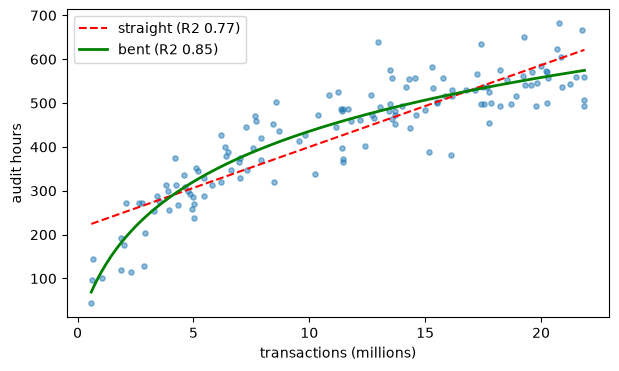

In [5]:
tx = np.sort(rng.uniform(0.3, 22, n))
hours = 180 * np.log(tx + 1) + rng.normal(0, 45, n)
d = pd.DataFrame({'tx': tx, 'hours': hours, 'log_tx': np.log(tx + 1)})
lin = smf.ols('hours ~ tx', data=d).fit()
log = smf.ols('hours ~ log_tx', data=d).fit()
print(f"straight line: R2 = {lin.rsquared:.2f}")
print(f"bent (log):    R2 = {log.rsquared:.2f}")

gx = np.linspace(tx.min(), tx.max(), 200)
plt.figure(figsize=(7, 4))
plt.scatter(tx, hours, s=14, alpha=0.5)
plt.plot(gx, lin.predict({'tx': gx}), 'r--', label=f'straight (R2 {lin.rsquared:.2f})')
plt.plot(gx, log.predict({'log_tx': np.log(gx + 1)}), 'g-', lw=2, label=f'bent (R2 {log.rsquared:.2f})')
plt.xlabel('transactions (millions)'); plt.ylabel('audit hours'); plt.legend(); plt.show()

### Takeaways

- A coefficient means *'holding the other drivers fixed'*, which is why a confounder (locations) can look important alone and vanish in context.
- Name each variable's role before you model: treatment, control, confounder, interaction.
- A dummy's coefficient is the gap between the groups.
- Compare models with **adjusted** R-squared, not R-squared.
- If the relationship bends, transform a predictor and fit a line to the new shape.